# Online Retail: Data Cleaning, EDA and Interactive Dashboard

| | |
|---|---|
| **Module** | Data Visualisation and Communication |
| **Assessment** | CA2 (60%) |
| **Lecturer** | Taufique Ahmed |
| **Student** | Matheus Leandro (2024657) |
| **Programme** | BSc (Hons) in Computing & IT |
| **Submission date** | xxxxx |
| **Video (5 min)** | xxxxx |
| **GitHub repository** | https://github.com/MatheusFerreiraL/dvc-ca2-online-retail |

## Contents

1. Introduction
2. Data loading and quality assessment
3. Data cleaning and preparation
4. Exploratory data analysis (static visualisations)
5. Interactive dashboard
6. Limitations
7. Conclusions
8. References

## 1. Introduction

In this CA I work as a data analyst for an online retailer. The notebook uses the Online Retail dataset, which has the transactions of a UK-based online shop between 01/12/2010 and 09/12/2011.

The notebook tries to answer these business questions:

1. Which products bring the most revenue?
2. Which countries matter most for the business, apart from the UK?
3. How do sales change over time (months, days of the week, hours)?
4. How do customers behave (order value, how many orders per customer)?

### Setup

The libraries below are the ones used in class: pandas and numpy for the data, matplotlib and seaborn for the static charts, plotly for interactive charts and ipywidgets for the dashboard filters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display

## 2. Data loading and quality assessment

This section loads the raw data and checks its quality before anything is changed. It looks at the structure of the data, missing values, duplicates, cancelled orders, invalid quantities and prices, codes that are not products, and outliers. Nothing is removed here: each problem is only measured, and the decisions are taken in Section 3.

In [2]:
# the dataset is not in the repository, see README.md
df = pd.read_excel('data/Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 2.1 Structure of the data

First I check the size of the table and the type of each column.

In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


The dataset has 541,909 rows and 8 columns. Each row is one product line inside an invoice, so one invoice can have many rows.

Some types need attention:

- `InvoiceDate` is already a date (`datetime64`), because `read_excel` reads the Excel date format. It still needs to be split into month, weekday and hour later.
- `CustomerID` is a decimal number (`float64`) even though it is an ID. This happens because the column has missing values, and pandas stores NaN only in decimal columns.
- `InvoiceNo` and `StockCode` are `object` columns because they mix numbers and text. Some invoice numbers start with a letter (for example "C536379"), and some stock codes are words such as "POST".

In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
# only the text columns, to see the number of unique values and the most common one
df[['InvoiceNo', 'StockCode', 'Description', 'Country']].describe()

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [7]:
print('First date:', df['InvoiceDate'].min())
print('Last date:', df['InvoiceDate'].max())

First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00


The numeric summary already shows problems. `Quantity` goes from -80,995 to 80,995 and `UnitPrice` has negative values, which a real sale cannot have. The median quantity is only 3 and the median price is about £2.08, so the maximum values are very far from a normal order. The mean and median of `CustomerID` have no meaning, because it is an identifier.

The text columns show 25,900 invoices, 4,070 stock codes and 38 countries. The United Kingdom has 495,478 rows, about 91% of the data, and no other country has more than 2% of the rows. The data runs from 01/12/2010 to 09/12/2011, which means December 2011 has only nine days and will look low in any monthly chart.

### 2.2 Missing values

In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
# share of missing values in each column, in %
(df.isnull().mean() * 100).round(2)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

Two columns have missing values. `CustomerID` is missing in 135,080 rows (24.93%) and `Description` in 1,454 rows (0.27%).

A missing customer is probably a guest purchase, where the order was not linked to an account. These rows still have a product, a quantity, a price and a country, so they are real sales. Dropping them would remove a quarter of the data, which would change the revenue by product, country and month a lot. The next cell checks the rows with no description.

In [10]:
no_description = df[df['Description'].isnull()]
print('Rows with no description:', len(no_description))
print('Of these, with unit price 0:', (no_description['UnitPrice'] == 0).sum())
print('Of these, with no customer:', no_description['CustomerID'].isnull().sum())

Rows with no description: 1454
Of these, with unit price 0: 1454
Of these, with no customer: 1454


All 1,454 rows with no description also have a price of 0 and no customer. They do not record a sale, so they look like stock corrections made inside the shop.

### 2.3 Duplicates

In [11]:
df.duplicated().sum()

np.int64(5268)

In [12]:
# keep=False marks every copy, so the repeated rows can be seen side by side
df[df.duplicated(keep=False)].sort_values(by=['InvoiceNo', 'StockCode']).head(6)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom


There are 5,268 rows that are exact copies of another row: same invoice, product, quantity, date, price and customer. Since a whole line is repeated, including the time to the minute, this is most likely the same line recorded twice. If they are kept, the revenue of those products would be counted twice.

### 2.4 Cancelled invoices

In this dataset, an invoice number that starts with the letter "C" is a cancellation. To find them I use `apply` with a lambda, as taught in class. Because `InvoiceNo` mixes numbers and text, each value is first changed to text with `str(x)`, and then `startswith('C')` checks the first letter.

In [13]:
df['IsCancelled'] = df['InvoiceNo'].apply(lambda x: str(x).startswith('C'))

cancelled = df[df['IsCancelled']]
print('Cancelled rows:', len(cancelled))
print('Cancelled invoices:', cancelled['InvoiceNo'].nunique())
print('Cancelled rows with a positive quantity:', (cancelled['Quantity'] > 0).sum())
print('Value of the cancelled rows (£):', round((cancelled['Quantity'] * cancelled['UnitPrice']).sum(), 2))

Cancelled rows: 9288
Cancelled invoices: 3836
Cancelled rows with a positive quantity: 0
Value of the cancelled rows (£): -896812.49


There are 9,288 cancelled rows in 3,836 invoices, and all of them have a negative quantity. Together they remove about £896,800 of value. These rows should not be counted as revenue. Their size is still worth reporting, because it shows how much value the shop loses to cancellations and returns, so Section 3 reports it.

I created a new column `IsCancelled` (True/False) so the same check can be reused in the cleaning step.

### 2.5 Invalid quantities and prices

In [14]:
print('Rows with quantity 0 or less:', (df['Quantity'] <= 0).sum())

not_cancelled_negative = df[(df['Quantity'] <= 0) & (df['IsCancelled'] == False)]
print('Of these, not cancellations:', len(not_cancelled_negative))
print('   ...with unit price 0:', (not_cancelled_negative['UnitPrice'] == 0).sum())
print('   ...with no customer:', not_cancelled_negative['CustomerID'].isnull().sum())

print('Rows with unit price 0:', (df['UnitPrice'] == 0).sum())
print('Rows with negative unit price:', (df['UnitPrice'] < 0).sum())

Rows with quantity 0 or less: 10624
Of these, not cancellations: 1336
   ...with unit price 0: 1336
   ...with no customer: 1336
Rows with unit price 0: 2515
Rows with negative unit price: 2


In [15]:
df[df['UnitPrice'] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,False
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,False


There are 10,624 rows with a quantity of 0 or less. Most are the cancellations from 2.4, but 1,336 are not. Those 1,336 rows have no customer and a price of 0, so they also look like stock adjustments and not customer returns.

2,515 rows have a price of 0, so they bring no revenue. The two rows with a negative price have the description "Adjust bad debt" and an invoice that starts with "A", so they are accounting corrections.

### 2.6 Codes that are not products

While looking at `StockCode`, I saw that normal products have codes that start with a number (for example 85123A). Some codes are words, such as "POST" (postage) or "M" (manual). The cell below lists every code whose first character is not a number. It uses `apply` with a lambda again, with the Python string method `isdigit()`.

In [16]:
not_number_code = df['StockCode'].apply(lambda x: str(x)[0].isdigit() == False)
codes = df[not_number_code]
codes['StockCode'].value_counts()

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
gift_0001_50       4
PADS               4
gift_0001_40       3
B                  3
DCGS0076           2
DCGS0070           2
DCGS0069           2
m                  1
DCGS0055           1
DCGS0072           1
DCGS0074           1
DCGS0057           1
DCGS0004           1
DCGS0073           1
DCGS0071           1
DCGS0068           1
DCGS0067           1
DCGS0066P          1
Name: count, dtype: int64

In [17]:
# one row per code, to read what each code is
codes.drop_duplicates(subset='StockCode')[['StockCode', 'Description']]

,StockCode,Description
45,POST,POSTAGE
141,D,Discount
1423,C2,CARRIAGE
1814,DOT,DOTCOM POSTAGE
2239,M,Manual
4406,BANK CHARGES,Bank Charges
14436,S,SAMPLES
14514,AMAZONFEE,AMAZON FEE
21326,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT
24906,DCGS0003,BOXED GLASS ASHTRAY


The first list counts the rows of each code and the second shows what each code is. Most of these codes are not products. They are postage (`POST`, `DOT`, `C2`), manual entries (`M`, `m`), discounts (`D`), samples (`S`), bank and Amazon fees (`BANK CHARGES`, `AMAZONFEE`), a charity commission (`CRUK`) and the bad debt adjustment (`B`). These are services or accounting entries, so they should not appear in a "top products" chart.

The other codes in the list (`DCGS...`, `gift_0001_...`, `PADS`) are real items, such as party bags, dog collars and gift vouchers, so they stay as products.

### 2.7 Outliers

I checked outliers with box plots and the IQR rule, as taught in class. The box plot shows that there are outliers, and the IQR limits (Q1 − 1.5 × IQR and Q3 + 1.5 × IQR) say how many there are.

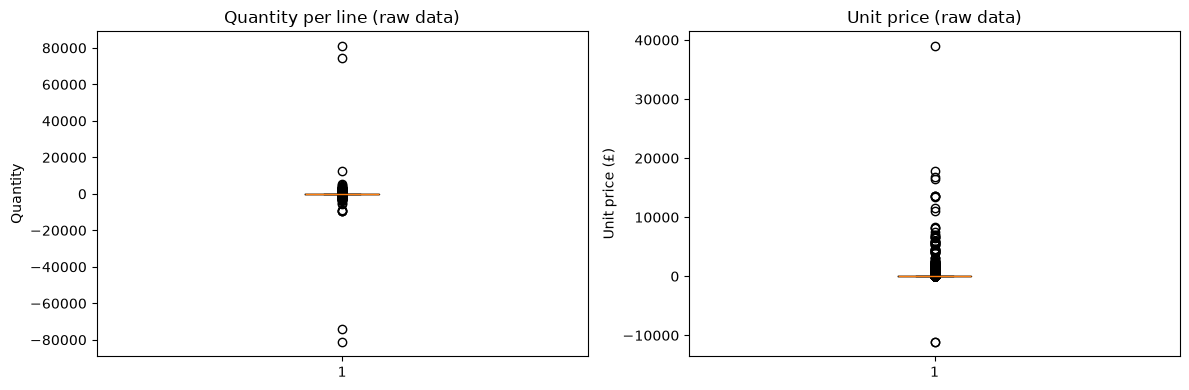

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.boxplot(df['Quantity'])
plt.title('Quantity per line (raw data)')
plt.ylabel('Quantity')

plt.subplot(1, 2, 2)
plt.boxplot(df['UnitPrice'])
plt.title('Unit price (raw data)')
plt.ylabel('Unit price (£)')

plt.tight_layout()
plt.show()

In [19]:
for column in ['Quantity', 'UnitPrice']:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    print(column, '| lower limit:', lower, '| upper limit:', upper, '| outlier rows:', len(outliers))

Quantity | lower limit: -12.5 | upper limit: 23.5 | outlier rows: 58619
UnitPrice | lower limit: -3.0700000000000003 | upper limit: 8.45 | outlier rows: 39627


In [20]:
# the largest quantities in the data
df.sort_values(by='Quantity', ascending=False).head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,False
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,False
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom,False


In [21]:
df[df['InvoiceNo'].isin(['C581484', 'C541433'])]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,True
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,True


In [22]:
# the highest unit prices in the data
df.sort_values(by='UnitPrice', ascending=False).head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,True
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom,True
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom,True
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom,True
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,True


The box plots are flat because a few extreme values stretch the axis. With the IQR rule, the upper limit for `Quantity` is only 23.5, so 58,619 rows count as outliers, and for `UnitPrice` it is £8.45, with 39,627 outlier rows.

In a retail business, many of these are not errors. The shop also sells to wholesalers, so orders of 100 or 500 units of a cheap item are normal sales. Removing everything above the IQR limit would delete about 10% of the rows and a big part of the real revenue. As we saw in class, an outlier is not always a mistake, and the decision depends on the domain.

The most extreme values are a different case. The two largest orders (80,995 and 74,215 units) were cancelled with a "C" invoice for the same quantity (C581484 and C541433), so they were probably typing mistakes. The third largest (12,540 units) has a price of 0. The highest prices (up to £38,970) belong to `M`, `AMAZONFEE` and other non-product codes. The cancellation, zero-price and non-product rules in Section 3 will remove these cases, and the decision on the remaining outliers is also made there.

### 2.8 Countries

In [23]:
df['Country'].value_counts()

Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European Community          61
RSA                         58


There are 38 country values. Two of them are not real countries: "Unspecified" (446 rows) and "European Community" (61 rows). They are kept for the totals, but they will not be compared as countries. "EIRE" is the name used for Ireland.

### 2.9 Summary of the data quality issues

| Issue | Rows affected | What it means for the business | Planned action (Section 3) |
|---|---|---|---|
| Missing `CustomerID` | 135,080 (24.93%) | Probably guest orders; still real sales | Keep for product, country and time analysis; leave out only from customer-level analysis |
| Missing `Description` | 1,454 (0.27%) | All have price 0 and no customer: not sales | Remove |
| Exact duplicate rows | 5,268 | Same line recorded twice; revenue counted twice | Remove, keep the first copy |
| Cancelled invoices ("C") | 9,288 rows, 3,836 invoices, about −£896,800 | Cancellations and returns, not sales | Remove from sales; report their size and value |
| Quantity ≤ 0 that is not a cancellation | 1,336 | Stock adjustments with price 0 | Remove |
| Unit price = 0 | 2,515 | No revenue | Remove |
| Negative unit price | 2 | "Adjust bad debt" accounting entries | Remove |
| Non-product codes | 11 codes (`POST`, `DOT`, `M`, `m`, `C2`, `D`, `S`, `B`, `BANK CHARGES`, `AMAZONFEE`, `CRUK`) | Postage, fees, discounts, manual entries | Remove from the product analysis |
| Outliers in `Quantity` and `UnitPrice` | 58,619 and 39,627 by the IQR rule | Mostly real wholesale orders; extremes are cancelled mistakes or fees | Extremes removed by the rules above; decision on the rest in Section 3 |
| "Unspecified" and "European Community" | 507 | Not real countries | Keep in totals, exclude from country comparisons |
| December 2011 | Only 1 to 9 December | Partial month | Flag in monthly charts |

Many rows have more than one issue (for example, a row can have no description and also a price of 0), so the rows in this table cannot simply be added up.

## 3. Data cleaning and preparation

This section applies the decisions from the summary in 2.9. The cleaning works on a copy of the raw data called `clean`, so `df` stays as it was and the two can be compared. After each step I record how many rows were removed, and the full log is shown in 3.12.

The order is: report the cancellations, fix the column types, remove the invalid rows, deal with missing values and country names, check the outliers again, and create the derived fields.

### 3.1 Cancellations as a business finding

Before the cancelled rows are removed, I measure how big they are compared with the sales. Here "gross sales" means the value of all rows that are not cancellations and have a positive quantity and price.

In [24]:
sales_rows = df[(df['IsCancelled'] == False) & (df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
gross_sales = (sales_rows['Quantity'] * sales_rows['UnitPrice']).sum()

cancelled = df[df['IsCancelled']]
cancelled_value = (cancelled['Quantity'] * cancelled['UnitPrice']).sum()

print('Gross sales (£):', round(gross_sales, 2))
print('Cancelled value (£):', round(cancelled_value, 2))
print('Cancelled value as % of gross sales:', round(-cancelled_value / gross_sales * 100, 1))
print('Cancelled invoices as % of all invoices:', round(cancelled['InvoiceNo'].nunique() / df['InvoiceNo'].nunique() * 100, 1))

Gross sales (£): 10666684.54
Cancelled value (£): -896812.49
Cancelled value as % of gross sales: 8.4
Cancelled invoices as % of all invoices: 14.8


In [25]:
# split the cancelled value into real products and the non-product codes found in 2.6
non_product_codes = ['POST', 'DOT', 'M', 'm', 'C2', 'D', 'S', 'B', 'BANK CHARGES', 'AMAZONFEE', 'CRUK']

cancelled_non_product = cancelled[cancelled['StockCode'].isin(non_product_codes)]
non_product_value = (cancelled_non_product['Quantity'] * cancelled_non_product['UnitPrice']).sum()

print('Cancelled value from non-product codes (£):', round(non_product_value, 2))
print('Cancelled value from products (£):', round(cancelled_value - non_product_value, 2))

Cancelled value from non-product codes (£): -418088.31
Cancelled value from products (£): -478724.18


In [26]:
# products with the highest cancelled value
cancelled_products = cancelled[cancelled['StockCode'].isin(non_product_codes) == False].copy()
cancelled_products['Value'] = cancelled_products['Quantity'] * cancelled_products['UnitPrice']
cancelled_products.groupby('Description')['Value'].sum().sort_values().head(5).round(2)

Description
PAPER CRAFT , LITTLE BIRDIE          -168469.60
MEDIUM CERAMIC TOP STORAGE JAR        -77479.64
REGENCY CAKESTAND 3 TIER               -9722.55
WHITE HANGING HEART T-LIGHT HOLDER     -6624.30
FAIRY CAKE FLANNEL ASSORTED COLOUR     -6591.42
Name: Value, dtype: float64

Cancellations are worth about 8.4% of gross sales, and 14.8% of all invoice numbers are cancellations. Almost half of the cancelled value (about £418,000) comes from non-product codes such as `M` (manual) and `AMAZONFEE`, so it comes from accounting entries. The product part is about £478,700. The products with the highest cancelled value include the two very large orders seen in 2.7.

For a manager this means the revenue in the rest of this notebook is gross sales, before cancellations. The real money kept by the shop is lower. I did not subtract the cancellations product by product, because a cancellation can be recorded weeks after the sale and cannot always be matched to the original line.

### 3.2 Copy of the data and column types

`InvoiceNo` and `StockCode` mix numbers and text (2.1). I convert both to text with `astype(str)`, so every value has the same type. This makes filters such as `== '581483'` work for every row. `InvoiceDate` is already `datetime64`, so it does not need converting. `CustomerID` stays as a decimal number, because it has missing values (see 3.8).

In [27]:
clean = df.copy()

clean['InvoiceNo'] = clean['InvoiceNo'].astype(str)
clean['StockCode'] = clean['StockCode'].astype(str)

# list to keep a log of every cleaning step
cleaning_log = []
clean.dtypes

InvoiceNo                 str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
IsCancelled              bool
dtype: object

### 3.3 Remove exact duplicates

The 5,268 exact copies from 2.3 are removed. `drop_duplicates()` keeps the first copy of each row by default (`keep='first'`).

In [28]:
rows_before = len(clean)
clean = clean.drop_duplicates()
cleaning_log.append({'Step': 'Exact duplicates', 'Rows removed': rows_before - len(clean), 'Rows left': len(clean)})
print('Rows removed:', rows_before - len(clean))

Rows removed: 5268


### 3.4 Remove cancelled invoices

The rows with an invoice starting with "C" are not sales, so they are removed. Their size was already reported in 3.1. The number is slightly lower than the 9,288 found in 2.4, because some cancelled rows were also duplicates and went in the step before.

In [29]:
rows_before = len(clean)
clean = clean[clean['IsCancelled'] == False]
cleaning_log.append({'Step': 'Cancelled invoices', 'Rows removed': rows_before - len(clean), 'Rows left': len(clean)})
print('Rows removed:', rows_before - len(clean))

Rows removed: 9251


### 3.5 Remove quantities of 0 or less

After the cancellations, the only rows left with a quantity of 0 or less are the 1,336 stock adjustments from 2.5. A sale needs at least one unit, so they are removed.

In [30]:
rows_before = len(clean)
clean = clean[clean['Quantity'] > 0]
cleaning_log.append({'Step': 'Quantity 0 or less', 'Rows removed': rows_before - len(clean), 'Rows left': len(clean)})
print('Rows removed:', rows_before - len(clean))

Rows removed: 1336


### 3.6 Remove prices of 0 or less

A row with a price of 0 brings no revenue, and a negative price is an accounting entry ("Adjust bad debt"). Both are removed. The next cell checks that this also removed every row with no `Description`, because in 2.2 all of them had a price of 0.

In [31]:
rows_before = len(clean)
clean = clean[clean['UnitPrice'] > 0]
cleaning_log.append({'Step': 'Unit price 0 or less', 'Rows removed': rows_before - len(clean), 'Rows left': len(clean)})
print('Rows removed:', rows_before - len(clean))
print('Rows with no description left:', clean['Description'].isnull().sum())

Rows removed: 1176
Rows with no description left: 0


### 3.7 Remove non-product codes

The 11 service and accounting codes from 2.6 are removed, so that the product analysis only has items that customers buy. `isin()` checks if each stock code is in the list. It was not used in class, but it is clearer than writing eleven `!=` conditions joined with `&`. `== False` keeps the rows whose code is outside the list.

In [32]:
rows_before = len(clean)
clean = clean[clean['StockCode'].isin(non_product_codes) == False]
cleaning_log.append({'Step': 'Non-product codes', 'Rows removed': rows_before - len(clean), 'Rows left': len(clean)})
print('Rows removed:', rows_before - len(clean))

Rows removed: 2307


### 3.8 Remove sales that were reversed straight away

Removing the "C" rows does not remove the original sale that was cancelled, because the sale and its cancellation are on different invoices. For most orders this cannot be matched (see 3.1), but three lines are clear mistakes and they are much larger than any other sale:

| Sale invoice | Product | Quantity | Value (£) | Reversed by | Minutes later |
|---|---|---|---|---|---|
| 581483 | PAPER CRAFT, LITTLE BIRDIE | 80,995 | 168,469.60 | C581484, same product and quantity | 12 |
| 541431 | MEDIUM CERAMIC TOP STORAGE JAR | 74,215 | 77,183.60 | C541433, same product and quantity | 16 |
| 556444 | PICNIC BASKET WICKER 60 PIECES | 60 | 38,970.00 | C556445, a manual (`M`) entry for exactly £38,970; C556448 also cancels 60 units of the same stock code | 3 (and 11) |

Each was cancelled by the same customer a few minutes after it was entered, so they were most likely entered by mistake. If they stayed, these three lines would add about £284,600 of revenue that was never paid, and the paper craft product and customer 16446 would look much more important than they are. The next two cells show the cancellations and the three sales, and then remove the sales.

In [33]:
# the cancellations that reversed these three sales
df[df['InvoiceNo'].isin(['C581484', 'C541433', 'C556445', 'C556448'])]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom,True
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,True
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95,15098.0,United Kingdom,True
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,True


In [34]:
reversed_lines = (((clean['InvoiceNo'] == '581483') & (clean['StockCode'] == '23843')) |
                  ((clean['InvoiceNo'] == '541431') & (clean['StockCode'] == '23166')) |
                  ((clean['InvoiceNo'] == '556444') & (clean['StockCode'] == '22502')))

display(clean[reversed_lines])

rows_before = len(clean)
clean = clean[reversed_lines == False]
cleaning_log.append({'Step': 'Sales reversed straight away', 'Rows removed': rows_before - len(clean), 'Rows left': len(clean)})
print('Rows removed:', rows_before - len(clean))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,False
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,United Kingdom,False
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,False


Rows removed: 3


Other cancellations cannot be matched with this confidence, for example when only part of an order is cancelled or the cancellation comes much later. Those original sales are kept, which is a limitation noted in 3.13.

### 3.9 Missing customer IDs

As decided in 2.2, rows with no `CustomerID` are kept, because they are real sales. Instead of filling the ID with a made-up value, I add a column `CustomerType` with `np.where` (taught on 21/09), so the dashboard and the charts can show or separate these sales. Customer-level analysis in Section 4 will only use the rows with an ID.

In [35]:
clean['CustomerType'] = np.where(clean['CustomerID'].isnull(), 'No customer ID', 'Registered customer')

print(clean['CustomerType'].value_counts())
print()
print(clean.isnull().sum())

CustomerType
Registered customer    391150
No customer ID         131418
Name: count, dtype: int64



InvoiceNo            0
StockCode            0
Description          0
Quantity             0
InvoiceDate          0
UnitPrice            0
CustomerID      131418
Country              0
IsCancelled          0
CustomerType         0
dtype: int64


### 3.10 Country names

Two country names are codes that a manager may not recognise, so I replace them with `replace()`: "EIRE" becomes "Ireland" and "RSA" becomes "South Africa". "Unspecified" and "European Community" stay in the data, but they will be left out when countries are compared.

In [36]:
clean['Country'] = clean['Country'].replace({'EIRE': 'Ireland', 'RSA': 'South Africa'})
clean['Country'].nunique()

38

### 3.11 Outliers after cleaning

I check the outliers again on the clean data, with the same IQR rule as in 2.7. To decide if they can be removed, I also measure how much revenue they carry. `TotalPrice` is created here, because it is needed for this check (it is explained in 3.12).

In [37]:
clean['TotalPrice'] = clean['Quantity'] * clean['UnitPrice']
total_revenue = clean['TotalPrice'].sum()

for column in ['Quantity', 'UnitPrice', 'TotalPrice']:
    Q1 = clean[column].quantile(0.25)
    Q3 = clean[column].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    outliers = clean[clean[column] > upper]
    print(column, '| upper limit:', round(upper, 2), '| outlier rows:', len(outliers),
          '| share of revenue:', round(outliers['TotalPrice'].sum() / total_revenue * 100, 1), '%')

Quantity | upper limit: 28.5 | outlier rows: 26812 | share of revenue: 35.8 %
UnitPrice | upper limit: 8.45 | outlier rows: 35771 | share of revenue: 11.9 %
TotalPrice | upper limit: 38.4 | outlier rows: 41121 | share of revenue: 49.1 %


In [38]:
clean[['Quantity', 'UnitPrice', 'TotalPrice']].describe()

,Quantity,UnitPrice,TotalPrice
count,522568.000000,522568.000000,522568.000000
mean,10.345352,3.273819,19.066001
std,37.852905,4.304220,65.305710
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.900000
75%,12.000000,4.130000,17.700000
max,4800.000000,649.500000,7144.720000


After cleaning there are no negative values, and the maximum quantity and price are realistic for a wholesale gift shop. The IQR rule still marks many rows, but they carry a large part of the business: the lines above the `TotalPrice` limit are 49.1% of all revenue. They come from wholesale customers who buy hundreds of units at a time.

So I keep all of them in the data. Removing or capping them would make the revenue totals wrong. Where the long tail makes a chart hard to read, for example a histogram of order values, Section 4 limits the values for that chart only with `clip()`, and says so in the chart's text.

### 3.12 Derived fields

The analysis needs some new columns, made from the existing ones:

| New column | How it is made | Why it is needed |
|---|---|---|
| `TotalPrice` | `Quantity * UnitPrice` | Revenue of each line, the main measure for products, countries and time |
| `YearMonth` | month of `InvoiceDate`, as text such as "2011-03" | Monthly trend and the date filter of the dashboard |
| `Weekday` | name of the day of `InvoiceDate` | Sales by day of the week |
| `Hour` | hour of `InvoiceDate` | Sales by time of day |
| `Region` | "United Kingdom" or "Outside UK", with `np.where` | Compare the home market with exports |
| `OrderValue` | total of `TotalPrice` for each invoice | Value of a whole order, for the order-size analysis and the "minimum order value" filter |

To get the month, weekday and hour I use the `.dt` accessor of pandas, which reads parts of a date column. It was not covered in class, but there is no simple way to split a date with the taught functions. `dt.to_period('M')` turns a date into its month, `dt.day_name()` gives the day name and `dt.hour` the hour.

In [39]:
clean['YearMonth'] = clean['InvoiceDate'].dt.to_period('M').astype(str)
clean['Weekday'] = clean['InvoiceDate'].dt.day_name()
clean['Hour'] = clean['InvoiceDate'].dt.hour
clean['Region'] = np.where(clean['Country'] == 'United Kingdom', 'United Kingdom', 'Outside UK')

clean[['InvoiceDate', 'YearMonth', 'Weekday', 'Hour', 'Country', 'Region', 'TotalPrice']].head()

,InvoiceDate,YearMonth,Weekday,Hour,Country,Region,TotalPrice
0,2010-12-01 08:26:00,2010-12,Wednesday,8,United Kingdom,United Kingdom,15.30
1,2010-12-01 08:26:00,2010-12,Wednesday,8,United Kingdom,United Kingdom,20.34
2,2010-12-01 08:26:00,2010-12,Wednesday,8,United Kingdom,United Kingdom,22.00
3,2010-12-01 08:26:00,2010-12,Wednesday,8,United Kingdom,United Kingdom,20.34
4,2010-12-01 08:26:00,2010-12,Wednesday,8,United Kingdom,United Kingdom,20.34


`OrderValue` is the sum of `TotalPrice` for each invoice. I calculate it with `groupby` and then add it back to every row with `merge` on `InvoiceNo` (both from the 21/09 class), so each line knows the value of its whole order.

In [40]:
order_value = clean.groupby('InvoiceNo')['TotalPrice'].sum().reset_index()
order_value = order_value.rename(columns={'TotalPrice': 'OrderValue'})

clean = pd.merge(clean, order_value, on='InvoiceNo')

# one value per invoice, so each order is counted once
order_value['OrderValue'].describe()

count    19770.000000
mean       503.959632
std       1146.113440
min          0.380000
25%        151.665000
50%        302.200000
75%        481.320000
max      52940.940000
Name: OrderValue, dtype: float64

There are 19,770 orders. A typical order is worth about £300 (median), but the mean is about £500, because a few large wholesale orders pull it up. This is the same long tail as in 3.11, and the reason Section 4 shows the median next to the mean.

### 3.13 Result of the cleaning

The column `IsCancelled` was only needed for the cleaning, so it is dropped. Then the cleaning log and a before/after comparison are shown.

In [41]:
clean = clean.drop(columns=['IsCancelled'])

log = pd.DataFrame(cleaning_log)
log

,Step,Rows removed,Rows left
0,Exact duplicates,5268,536641
1,Cancelled invoices,9251,527390
2,Quantity 0 or less,1336,526054
3,Unit price 0 or less,1176,524878
4,Non-product codes,2307,522571
5,Sales reversed straight away,3,522568


In [42]:
comparison = pd.DataFrame({
    'Raw data': [len(df), df['InvoiceNo'].nunique(), df['StockCode'].nunique(), df['CustomerID'].nunique()],
    'Clean data': [len(clean), clean['InvoiceNo'].nunique(), clean['StockCode'].nunique(), clean['CustomerID'].nunique()]
}, index=['Rows', 'Invoices', 'Stock codes', 'Customers with ID'])

comparison['% kept'] = (comparison['Clean data'] / comparison['Raw data'] * 100).round(1)
comparison

,Raw data,Clean data,% kept
Rows,541909,522568,96.4
Invoices,25900,19770,76.3
Stock codes,4070,3912,96.1
Customers with ID,4372,4333,99.1


In [43]:
print('Revenue of the clean data (£):', round(clean['TotalPrice'].sum(), 2))
print('Period:', clean['InvoiceDate'].min(), 'to', clean['InvoiceDate'].max())
clean.info()

Revenue of the clean data (£): 9963281.93
Period: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
<class 'pandas.DataFrame'>
RangeIndex: 522568 entries, 0 to 522567
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     522568 non-null  str           
 1   StockCode     522568 non-null  str           
 2   Description   522568 non-null  object        
 3   Quantity      522568 non-null  int64         
 4   InvoiceDate   522568 non-null  datetime64[us]
 5   UnitPrice     522568 non-null  float64       
 6   CustomerID    391150 non-null  float64       
 7   Country       522568 non-null  str           
 8   CustomerType  522568 non-null  str           
 9   TotalPrice    522568 non-null  float64       
 10  YearMonth     522568 non-null  str           
 11  Weekday       522568 non-null  str           
 12  Hour          522568 non-null  int32         
 13  Region        522568 non-null  str   

The cleaning removed about 3.6% of the rows and kept 96.4% of them. The number of invoices fell more (76.3% kept), because each cancellation invoice was a separate invoice number and all of them were removed. The clean table has no missing values except `CustomerID`, which is kept on purpose and labelled with `CustomerType`. Its revenue is about £9.96 million of gross sales.

The cleaning has some limitations:

- Revenue is gross sales. Cancellations (about 8.4% of gross sales) are reported in 3.1 but not subtracted product by product.
- About a quarter of the rows have no customer ID, so any customer analysis covers only the registered customers.
- The non-product codes were chosen by reading their descriptions. Another analyst could make a slightly different list.
- Only the three clearest reversed sales were removed. Other cancelled orders still count in the gross sales.
- The dataset has no cost or profit columns, so the analysis covers revenue only.
- December 2011 has only nine days.

## 4. Exploratory data analysis (static visualisations)

This section explores the clean data to answer the four business questions from Section 1. It starts with descriptive statistics and then shows static charts about time, products, countries, order values and customers. Each chart follows the pattern used in class: the **objective** of the chart and **why this chart type** fits the question come before the code, and **what it shows** comes after it.

All revenue figures are gross sales after cleaning (see 3.13). To keep the axes easy to read, most charts show revenue in thousands of pounds (£k).

### 4.1 Descriptive statistics

The statistics of each line (quantity, price, line value) were shown in 3.11. Here I look at the business as a whole, and then at two levels that a manager thinks in: orders and customers. First, a table of key figures.

In [44]:
# key figures of the clean data
key_figures = pd.DataFrame({
    'Value': [round(clean['TotalPrice'].sum(), 2),
              clean['InvoiceNo'].nunique(),
              clean['CustomerID'].nunique(),
              clean['StockCode'].nunique(),
              clean['Country'].nunique(),
              round(order_value['OrderValue'].mean(), 2),
              round(order_value['OrderValue'].median(), 2)]
}, index=['Revenue (£)', 'Orders', 'Customers with ID', 'Products (stock codes)', 'Countries',
          'Mean order value (£)', 'Median order value (£)'])
key_figures

,Value
Revenue (£),9963281.93
Orders,19770.00
Customers with ID,4333.00
Products (stock codes),3912.00
Countries,38.00
Mean order value (£),503.96
Median order value (£),302.20


Next I build two smaller tables that several charts in this section use:

- `orders` has one row per invoice. `drop_duplicates(subset='InvoiceNo')` keeps the first line of each invoice. This is safe because the order value, country and customer are the same on every line of an invoice (I checked this with `nunique` while preparing the notebook).
- `customers` has one row per registered customer, with their revenue and number of orders. The two values come from two `groupby` results joined with `merge`, as in 3.12.

In [45]:
# one row per order
orders = clean.drop_duplicates(subset='InvoiceNo')[['InvoiceNo', 'InvoiceDate', 'Country', 'Region', 'CustomerType', 'OrderValue']].copy()

# one row per registered customer: revenue and number of orders
registered = clean[clean['CustomerID'].notnull()]
customer_revenue = registered.groupby('CustomerID')['TotalPrice'].sum().reset_index()
customer_orders = registered.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()

customers = pd.merge(customer_revenue, customer_orders, on='CustomerID')
customers = customers.rename(columns={'TotalPrice': 'Revenue', 'InvoiceNo': 'Orders'})

print('Orders:', len(orders), '| Registered customers:', len(customers))
customers[['Revenue', 'Orders']].describe().round(2)

Orders: 19770 | Registered customers: 4333


,Revenue,Orders
count,4333.00,4333.00
mean,1950.75,4.25
std,8441.49,7.64
min,2.90,1.00
25%,303.97,1.00
50%,661.32,2.00
75%,1625.97,5.00
max,279138.02,206.00


In [46]:
# orders and revenue by customer type
by_customer_type = orders.groupby('CustomerType')['OrderValue'].agg(['count', 'mean', 'median', 'sum']).round(2)
by_customer_type['% of revenue'] = (by_customer_type['sum'] / by_customer_type['sum'].sum() * 100).round(1)
by_customer_type

,count,mean,median,sum,% of revenue
CustomerType,,,,,
No customer ID,1371,1101.88,360.33,1510677.49,15.2
Registered customer,18399,459.41,301.63,8452604.44,84.8


**What it shows:** the shop sold about £9.96 million in 19,770 orders, to 4,333 registered customers in 38 countries, with 3,912 different products. A typical registered customer (median) spent about £661 in two orders. The mean is much higher, about £1,951, because a few customers spend far more than the rest: the largest one spent about £279,100. Order values have the same long tail (3.12), so in this section I use the median as the "typical" value and show the mean next to it.

Orders with no customer ID are only 1,371 of the 19,770 orders (about 7%), but their mean value is about £1,102, more than twice the mean of registered orders (£459). Together they bring 15.2% of the revenue. These sales are too large to ignore, which supports the decision in 3.9 to keep them.

### 4.2 Sales over time

**Objective:** see how monthly revenue changes during the year and whether there is a seasonal pattern (business question 3).

**Why this chart:** a line chart is the chart taught for a trend over time, because the line joins the months in order and shows the direction of change. A bar or pie chart would not show the trend as clearly. I add a 3-month moving average with `rolling(window=3).mean()`, as in the 02/11 class, to smooth the changes from one month to the next. The first two months have no moving average, because the window needs three values.

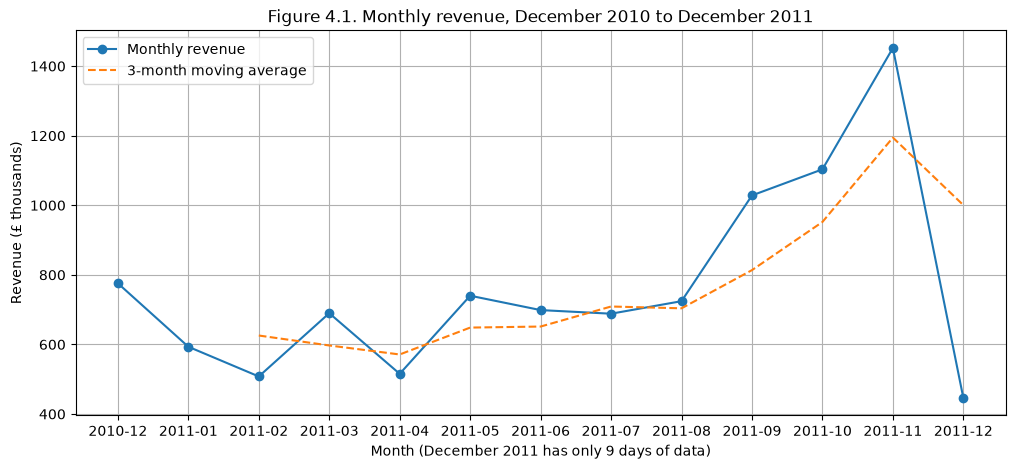

,YearMonth,Revenue (£k),Moving average (£k),Orders
0,2010-12,775.7,NaN,1550
1,2011-01,593.3,NaN,1080
2,2011-02,507.9,625.6,1093
3,2011-03,689.8,597.0,1440
4,2011-04,515.5,571.1,1235
5,2011-05,740.0,648.4,1668
6,2011-06,698.7,651.4,1524
7,2011-07,688.3,709.0,1452
8,2011-08,724.3,703.8,1339
9,2011-09,1028.3,813.6,1818


In [47]:
# revenue and number of orders per month
monthly = clean.groupby('YearMonth')['TotalPrice'].sum().reset_index()
monthly['Revenue (£k)'] = (monthly['TotalPrice'] / 1000).round(1)
monthly['Moving average (£k)'] = monthly['Revenue (£k)'].rolling(window=3).mean().round(1)

monthly_orders = clean.groupby('YearMonth')['InvoiceNo'].nunique().reset_index()
monthly_orders = monthly_orders.rename(columns={'InvoiceNo': 'Orders'})
monthly = pd.merge(monthly, monthly_orders, on='YearMonth')

plt.figure(figsize=(12, 5))
plt.plot(monthly['YearMonth'], monthly['Revenue (£k)'], marker='o', label='Monthly revenue')
plt.plot(monthly['YearMonth'], monthly['Moving average (£k)'], linestyle='--', label='3-month moving average')
plt.title('Figure 4.1. Monthly revenue, December 2010 to December 2011')
plt.xlabel('Month (December 2011 has only 9 days of data)')
plt.ylabel('Revenue (£ thousands)')
plt.legend()
plt.grid(True)
plt.show()

monthly[['YearMonth', 'Revenue (£k)', 'Moving average (£k)', 'Orders']]

**What it shows:** from January to August 2011 revenue stays between about £508k and £740k a month. From September it rises fast and reaches its peak in November 2011, at about £1.45 million. This is almost three times February (£508k), the weakest month. December 2010 (£776k) is also higher than the months after it, which fits the same pattern. The number of orders follows the revenue (1,093 in February and 2,751 in November), so most of the growth comes from more orders, while the average order grows only a little. The products are mostly gifts and decorations (4.4), so the most likely reason is that customers buy stock for Christmas.

December 2011 looks low only because the data stops on 9 December. The data covers only 13 months, so this is one season: I cannot confirm that the pattern repeats every year.

### 4.3 Sales by day of the week and hour of the day

**Objective:** find which days and hours bring the most revenue (business question 3). This can help to plan staff, stock and the timing of marketing emails.

**Why this chart:** comparing values between categories is a job for a bar chart. Days and hours have a natural order, so the bars keep that order and are not sorted by size. The two charts answer the same question, so they are shown side by side with `plt.subplot(1, 2, n)` (28/09).

Days with sales: ['Friday', 'Monday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']


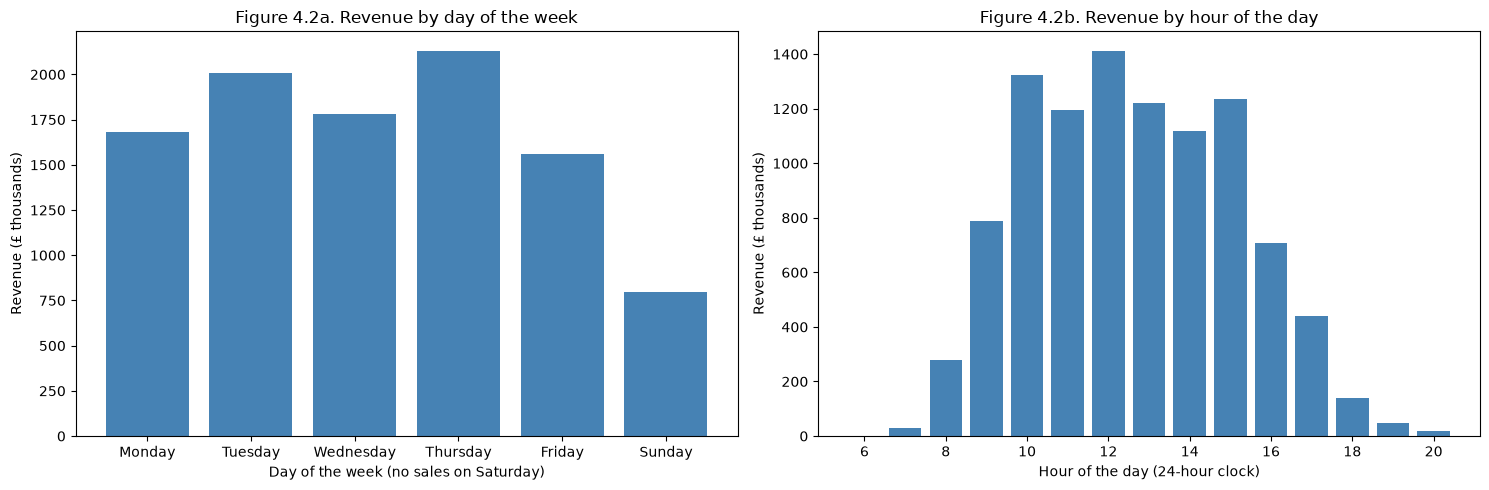

Share of revenue by day (%):
Weekday
Monday       16.9
Tuesday      20.2
Wednesday    17.9
Thursday     21.4
Friday       15.7
Sunday        8.0
Name: TotalPrice, dtype: float64
Share of revenue from 10:00 to 15:59 (%): 75.4


In [48]:
by_day = clean.groupby('Weekday')['TotalPrice'].sum() / 1000
print('Days with sales:', sorted(by_day.index.tolist()))

# there are no sales on Saturday, so it is not in the list
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
by_day = by_day.loc[day_order]

by_hour = clean.groupby('Hour')['TotalPrice'].sum() / 1000

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.bar(by_day.index, by_day.values, color='steelblue')
plt.title('Figure 4.2a. Revenue by day of the week')
plt.xlabel('Day of the week (no sales on Saturday)')
plt.ylabel('Revenue (£ thousands)')

plt.subplot(1, 2, 2)
plt.bar(by_hour.index, by_hour.values, color='steelblue')
plt.title('Figure 4.2b. Revenue by hour of the day')
plt.xlabel('Hour of the day (24-hour clock)')
plt.ylabel('Revenue (£ thousands)')

plt.tight_layout()
plt.show()

print('Share of revenue by day (%):')
print((by_day / by_day.sum() * 100).round(1))
print('Share of revenue from 10:00 to 15:59 (%):', round(by_hour.loc[10:15].sum() / by_hour.sum() * 100, 1))

**What it shows:** Thursday is the strongest day (21.4% of revenue), followed by Tuesday (20.2%). Sunday brings only 8.0%, and there are no sales at all on Saturday, which suggests that the shop does not take or process orders on that day. During the day, sales start at about 7:00, grow quickly in the morning and peak at 12:00. The six hours from 10:00 to 15:59 bring 75.4% of the revenue, and very little is sold after 18:00. This matches the working hours of business customers, which fits a shop that sells mainly to wholesalers.

### 4.4 Top products

**Objective:** find the products that bring the most revenue and the products that sell the most units (business question 1).

**Why this chart:** a horizontal bar chart (`barh`, 05/10) is good for a ranking of categories with long names, because the names can be read on the left. The bars are sorted, so the largest product is at the top. I show revenue and units side by side, because a cheap product can sell many units and still bring little money. The products are grouped by `Description`, so that a manager can read the names. Some stock codes have more than one description, so a few products could be split across two names. This is a small limitation of the ranking.

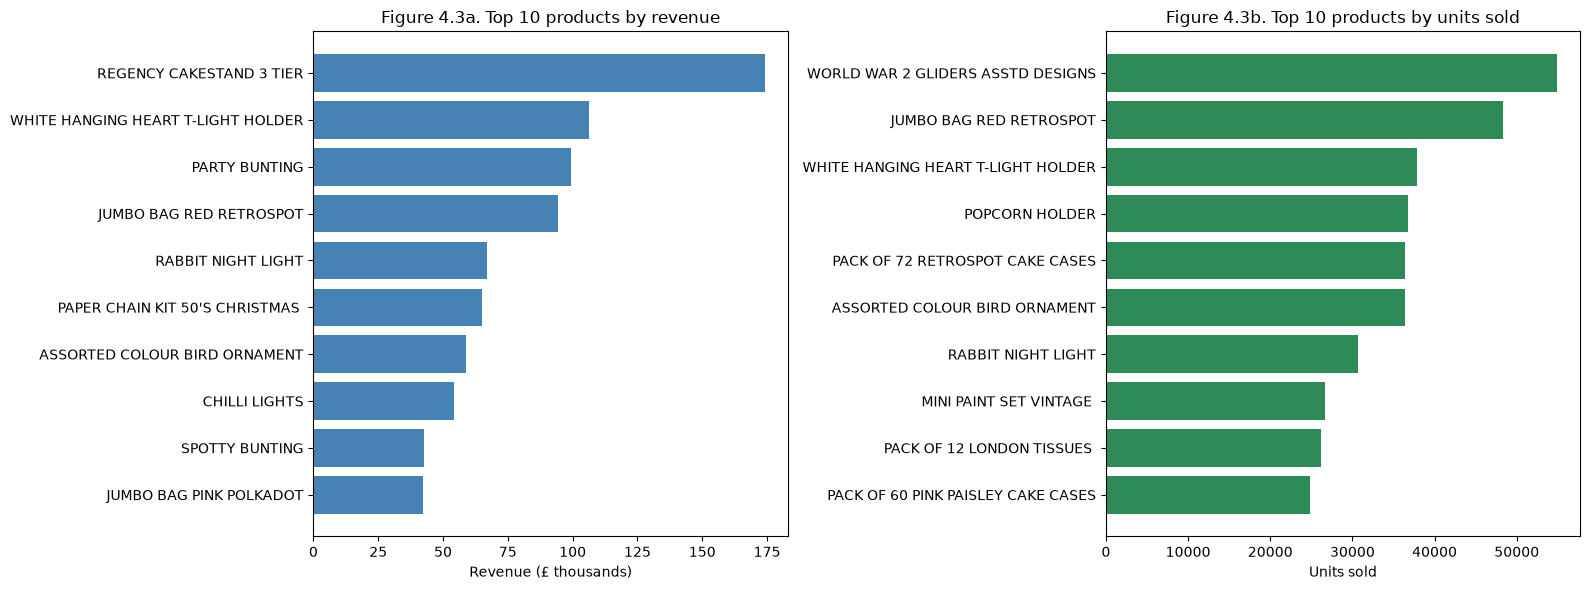

Share of revenue from the top 10 products: 8.1 %
Products in both lists: ['WHITE HANGING HEART T-LIGHT HOLDER', 'JUMBO BAG RED RETROSPOT', 'RABBIT NIGHT LIGHT', 'ASSORTED COLOUR BIRD ORNAMENT']


In [49]:
total_revenue_k = clean['TotalPrice'].sum() / 1000

top_revenue = (clean.groupby('Description')['TotalPrice'].sum() / 1000).sort_values(ascending=False).head(10)
top_units = clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(16, 6))

# sort_values() puts the smallest bar first, so the largest one is drawn at the top
plt.subplot(1, 2, 1)
plt.barh(top_revenue.sort_values().index, top_revenue.sort_values().values, color='steelblue')
plt.title('Figure 4.3a. Top 10 products by revenue')
plt.xlabel('Revenue (£ thousands)')

plt.subplot(1, 2, 2)
plt.barh(top_units.sort_values().index, top_units.sort_values().values, color='seagreen')
plt.title('Figure 4.3b. Top 10 products by units sold')
plt.xlabel('Units sold')

plt.tight_layout()
plt.show()

print('Share of revenue from the top 10 products:', round(top_revenue.sum() / total_revenue_k * 100, 1), '%')
print('Products in both lists:', [p for p in top_revenue.index if p in top_units.index])

In [50]:
# median unit price of the product with the most units sold
clean[clean['Description'] == 'WORLD WAR 2 GLIDERS ASSTD DESIGNS']['UnitPrice'].median()

np.float64(0.29)

**What it shows:** the "Regency cakestand 3 tier" brings the most revenue (about £174k), but this is only 1.7% of the total. The ten best products together bring 8.1% of the revenue, so the business does not depend on a few products. Its revenue is spread over thousands of items, mostly home decoration, party and Christmas products, which also explains the autumn peak in 4.2.

The two rankings are quite different: only four products are in both lists. The product with the most units, "World War 2 gliders", sold about 55,000 units at a median price of £0.29, so it is not in the revenue top 10. For decisions on stock and promotions, the revenue ranking matters more, but the units ranking shows which items need the most stock space and picking work.

### 4.5 Countries

**Objective:** see how much revenue comes from the UK and from other countries, and which foreign markets matter most (business question 2).

**Why this chart:** a pie chart shows part of a whole, and the class rule is to use it only for a few categories. Here it has just two (UK and outside the UK), so it is easy to read. To rank the other countries I use a horizontal bar chart, because a pie with 37 slices would be impossible to read. The UK is left out of the bar chart: with 85% of the revenue it would make the other bars too small to compare. "Unspecified" and "European Community" are also left out, as said in 3.10.

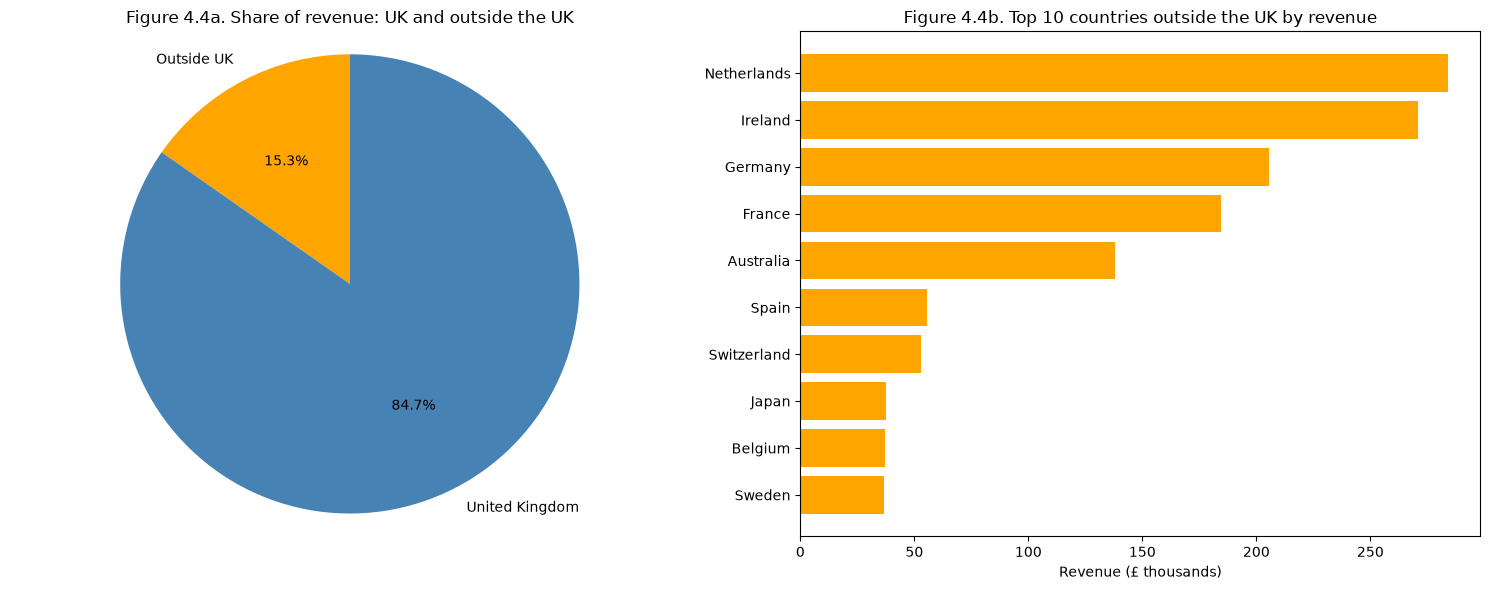

Share of the revenue outside the UK (%):
Country
Netherlands    18.6
Ireland        17.8
Germany        13.5
France         12.1
Australia       9.1
Spain           3.7
Switzerland     3.5
Japan           2.5
Belgium         2.4
Sweden          2.4
Name: TotalPrice, dtype: float64


In [51]:
by_region = clean.groupby('Region')['TotalPrice'].sum()

outside_uk = clean[(clean['Region'] == 'Outside UK') &
                   (clean['Country'] != 'Unspecified') &
                   (clean['Country'] != 'European Community')]
top_countries = (outside_uk.groupby('Country')['TotalPrice'].sum() / 1000).sort_values(ascending=False).head(10)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.pie(by_region.values, labels=by_region.index, autopct='%1.1f%%', startangle=90, colors=['orange', 'steelblue'])
plt.title('Figure 4.4a. Share of revenue: UK and outside the UK')
plt.axis('equal')

plt.subplot(1, 2, 2)
plt.barh(top_countries.sort_values().index, top_countries.sort_values().values, color='orange')
plt.title('Figure 4.4b. Top 10 countries outside the UK by revenue')
plt.xlabel('Revenue (£ thousands)')

plt.tight_layout()
plt.show()

outside_total_k = by_region['Outside UK'] / 1000
print('Share of the revenue outside the UK (%):')
print((top_countries / outside_total_k * 100).round(1))

**What it shows:** the UK brings 84.7% of the revenue, so the business is mainly a home-market business. The remaining 15.3% (about £1.52 million) comes mostly from a few European countries. The Netherlands (about £284k), Ireland (£271k), Germany (£205k) and France (£184k) bring together about 62% of the revenue from outside the UK, and Australia is the largest market outside Europe. After the top five, each country brings only a small amount. For a manager, these four or five countries are the obvious markets to protect or grow, and the dashboard in Section 5 lets them be explored one by one.

### 4.6 Distribution of order values

**Objective:** see how large a typical order is and how many very large orders there are (business question 4). This also helps to choose a sensible range for the "minimum order value" filter of the dashboard.

**Why this chart:** a histogram shows the distribution of a continuous variable: it counts how many orders fall in each range of values. The long tail (the largest order is about £52,900) would push almost every order into the first bar. So, for this chart only, I cap the values at £2,000 with `clip(upper=2000)`, which was approved for this CA (capping was taught as an idea on 19/10). Orders above £2,000 are counted in the last bar. The data itself is not changed.

Orders above £2,000: 647 | share of orders: 3.3 % | share of revenue: 30.0 %


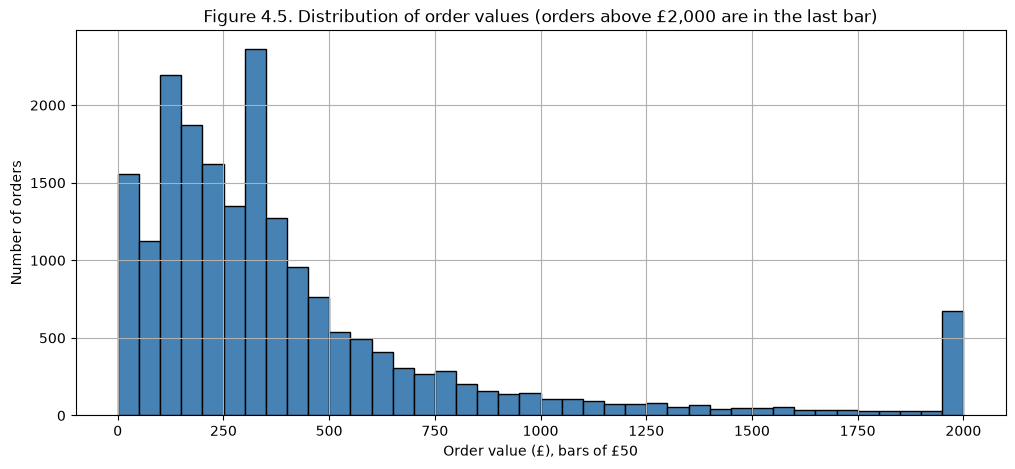

In [52]:
big_orders = orders[orders['OrderValue'] > 2000]
print('Orders above £2,000:', len(big_orders), '| share of orders:', round(len(big_orders) / len(orders) * 100, 1), '%',
      '| share of revenue:', round(big_orders['OrderValue'].sum() / orders['OrderValue'].sum() * 100, 1), '%')

# capped copy, only for the chart
order_value_capped = orders['OrderValue'].clip(upper=2000)

plt.figure(figsize=(12, 5))
plt.hist(order_value_capped, bins=40, edgecolor='black', color='steelblue')
plt.title('Figure 4.5. Distribution of order values (orders above £2,000 are in the last bar)')
plt.xlabel('Order value (£), bars of £50')
plt.ylabel('Number of orders')
plt.grid(True)
plt.show()

**What it shows:** the distribution is skewed to the right. Most orders are small: half of them are between about £152 and £481 (3.12), and the highest bar is £300–350. The bar at £2,000 shows the long tail: 647 orders (3.3% of all orders) are worth more than £2,000, but together they bring 30.0% of the revenue. In the dashboard, a minimum order value filter between £0 and about £2,000 covers almost all orders and lets a manager focus on these large orders.

### 4.7 Order values by region and customer type

**Objective:** compare the size of orders from the UK with orders from other countries, and orders from registered customers with orders that have no customer ID (business questions 2 and 4).

**Why this chart:** a box plot shows the distribution of a numeric variable for each group: the median, the quartiles and the outliers (28/09, 05/10). It makes the groups easy to compare side by side. I use `sns.boxplot` with the same £2,000 cap as in 4.6, otherwise the boxes would be too flat to read. The cap is above the third quartile of every group, so the boxes and medians are exact; only the outlier points above £2,000 are drawn at £2,000.

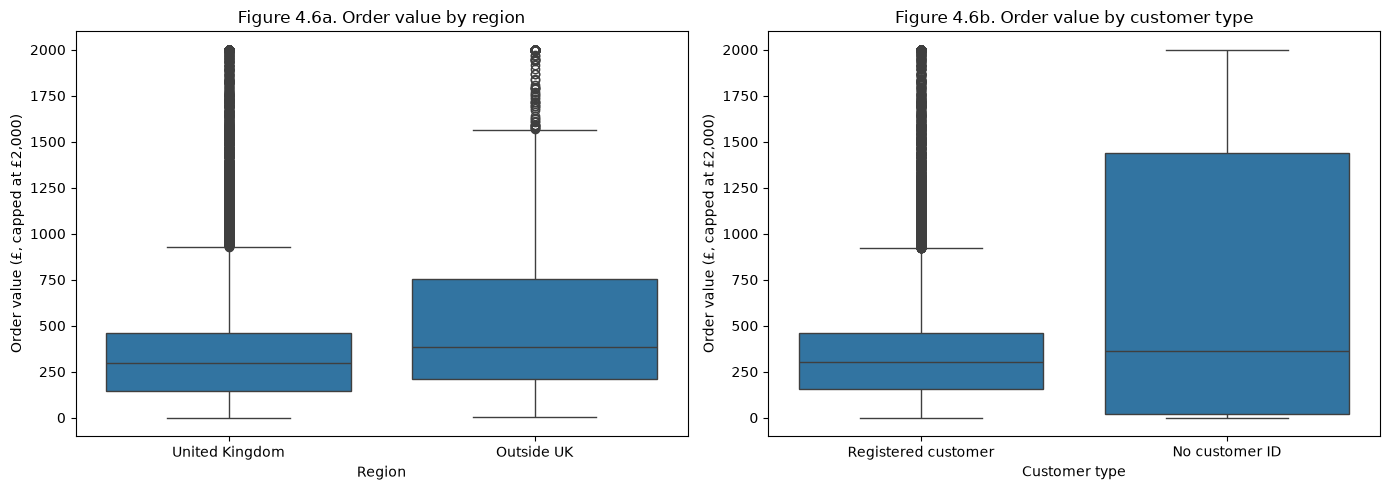

,count,median,mean
Region,,,
Outside UK,1872,385.28,813.45
United Kingdom,17898,299.56,471.59


In [53]:
orders['OrderValueCapped'] = orders['OrderValue'].clip(upper=2000)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Region', y='OrderValueCapped', data=orders)
plt.title('Figure 4.6a. Order value by region')
plt.xlabel('Region')
plt.ylabel('Order value (£, capped at £2,000)')

plt.subplot(1, 2, 2)
sns.boxplot(x='CustomerType', y='OrderValueCapped', data=orders)
plt.title('Figure 4.6b. Order value by customer type')
plt.xlabel('Customer type')
plt.ylabel('Order value (£, capped at £2,000)')

plt.tight_layout()
plt.show()

orders.groupby('Region')['OrderValue'].agg(['count', 'median', 'mean']).round(2)

In [54]:
# quartiles of the order value for each customer type
orders.groupby('CustomerType')['OrderValue'].quantile([0.25, 0.5, 0.75]).round(2)

CustomerType             
No customer ID       0.25      18.48
                     0.50     360.33
                     0.75    1438.89
Registered customer  0.25     157.12
                     0.50     301.63
                     0.75     462.98
Name: OrderValue, dtype: float64

**What it shows:** orders from outside the UK are larger. Their median is about £385, against about £300 for UK orders, and their mean is £813 against £472. One possible reason is delivery cost: a foreign customer may order less often but buy more each time. This cannot be checked with this data, because it has no delivery information. In both regions there are many outliers above the whiskers, which are the large wholesale orders seen in 4.6.

Orders with no customer ID look very different from registered orders. Their median is close (£360 against £302), but their box is much taller: a quarter of them are below about £18 and a quarter are above about £1,439. So this group mixes many very small orders with many large ones, and the large ones explain its high mean (£1,102 against £459, see 4.1). The box reaches the £2,000 cap, so this group has no separate outlier points. Without a customer ID I cannot say who these buyers are, which is a limitation for the customer analysis.

### 4.8 Customers: orders and revenue

**Objective:** see how revenue is spread across customers and whether customers who order more often also spend more (business question 4). This part covers only the registered customers (3.9).

**Why this chart:** a scatter plot shows the relationship between two numeric variables, here the number of orders and the revenue of each customer (one dot per customer). As in the 05/10 class, I confirm what the chart shows with the correlation value. The largest customers would push all the other dots into one corner, so the chart shows the 99% of customers below the 99th percentile of revenue. The correlation and the other figures are calculated on all customers.

         Orders  Revenue
Orders     1.00     0.58
Revenue    0.58     1.00

Customers with only one order: 34.7 %
Revenue share of the top 10% of customers: 60.2 %
Customers shown in the chart: 4289 of 4333 | revenue limit (£): 17356.08


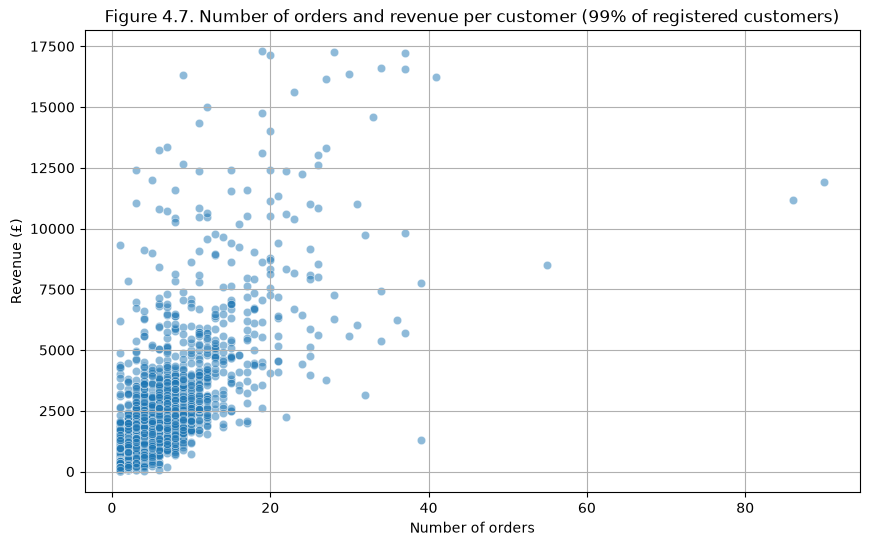

In [55]:
print(customers[['Orders', 'Revenue']].corr().round(2))
print()
print('Customers with only one order:', round((customers['Orders'] == 1).sum() / len(customers) * 100, 1), '%')

# share of the revenue that comes from the top 10% of customers
top_customers = customers.sort_values(by='Revenue', ascending=False).head(int(len(customers) * 0.1))
print('Revenue share of the top 10% of customers:', round(top_customers['Revenue'].sum() / customers['Revenue'].sum() * 100, 1), '%')

revenue_limit = customers['Revenue'].quantile(0.99)
most_customers = customers[customers['Revenue'] <= revenue_limit]
print('Customers shown in the chart:', len(most_customers), 'of', len(customers), '| revenue limit (£):', round(revenue_limit, 2))

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Orders', y='Revenue', data=most_customers, alpha=0.5)
plt.title('Figure 4.7. Number of orders and revenue per customer (99% of registered customers)')
plt.xlabel('Number of orders')
plt.ylabel('Revenue (£)')
plt.grid(True)
plt.show()

**What it shows:** the dots go up from left to right, and the correlation between orders and revenue is 0.58, a moderate positive relationship: customers who order more often usually spend more in total. The spread is wide, though. Some customers with few orders spend a lot, because their orders are large.

Revenue is very concentrated. The top 10% of customers (433 customers) bring 60.2% of the revenue of registered customers, while 34.7% of the customers ordered only once. For a manager, the small group of large repeat customers is the most valuable one to keep, and turning one-time buyers into repeat buyers is a clear chance to grow.

### 4.9 Summary of the exploratory analysis

| Business question | Main finding | Where |
|---|---|---|
| 1. Which products bring the most revenue? | The cakestand, the T-light holder and party bunting lead, but the top 10 products bring only 8.1% of revenue. Revenue is spread over thousands of gift and decoration items. Best sellers by units are often cheap items. | 4.4, Figures 4.3a–b |
| 2. Which countries matter most apart from the UK? | The UK brings 84.7% of revenue. Outside the UK, the Netherlands, Ireland, Germany and France bring about 62% of foreign revenue. Foreign orders are larger (median £385 against £300). | 4.5, 4.7, Figures 4.4a–b, 4.6a |
| 3. How do sales change over time? | Strong rise from September to a peak in November 2011 (£1.45 million), driven by more orders. Thursday is the best day, there are no Saturday sales, and 75% of revenue comes between 10:00 and 16:00. | 4.2, 4.3, Figures 4.1, 4.2a–b |
| 4. How do customers behave? | A typical order is about £300, but 3.3% of orders (above £2,000) bring 30% of revenue. The top 10% of customers bring 60% of registered revenue, and about a third of customers ordered only once. | 4.1, 4.6, 4.8, Figures 4.5, 4.6b, 4.7 |

These findings guide the dashboard in Section 5: it needs a date filter for the seasonal pattern, a country filter for the foreign markets, and a minimum order value filter for the large orders.

## 5. Interactive dashboard

## 6. Limitations

## 7. Conclusions

## 8. References